In [1]:
import re

def extraer_dosis(archivo, region_objetivo=700):
    with open(archivo, "r", encoding="utf-8") as f:
        contenido = f.read()

    patron = (
        rf"^\s*\d+\s+{region_objetivo}\s+"
        rf"[\d.Ee+-]+\s+([\d.Ee+-]+)\s+[\d.Ee+-]+"
    )

    coincidencia = re.search(patron, contenido, re.MULTILINE)

    if coincidencia:
        return float(coincidencia.group(1))

    raise ValueError(
        f"No se encontró la dosis para la región {region_objetivo}"
    )


archivo = r"..\out\dosis_region5.out"

dosis = extraer_dosis(archivo)

print(f"Dosis en región 5: {dosis} Gy/source")

Dosis en región 5: 0.51374 Gy/source


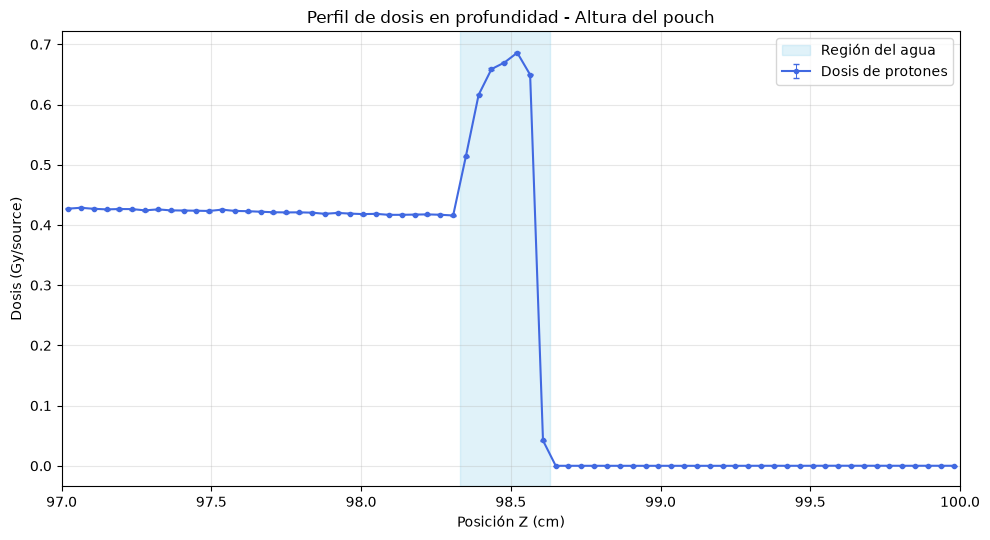

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

archivo = Path("../out/bragg_pouch_water.out")

datos = []
leyendo = False

for linea in archivo.read_text().splitlines():
    if linea.strip().startswith("#  z-lower"):
        leyendo = True
        continue

    if leyendo:
        if linea.strip().startswith("#   sum"):
            break

        valores = linea.split()

        if len(valores) == 4:
            try:
                datos.append([float(v) for v in valores])
            except ValueError:
                continue

datos = np.array(datos)

z = (datos[:, 0] + datos[:, 1]) / 2
dosis = datos[:, 2]
error = dosis * datos[:, 3]

fig, ax = plt.subplots(figsize=(10, 5.5))

ax.errorbar(
    z, dosis, yerr=error,
    fmt="o-", color="royalblue",
    markersize=3, linewidth=1.5,
    capsize=2, elinewidth=0.7,
    label="Dosis de protones"
)

# para el pouch normal iba de:  98, 58 ; 98, 38 (2 mm); ahora tiene 3 mm de agua

ax.axvspan(
    98.33, 98.63,
    color="skyblue", alpha=0.25,
    label="Región del agua"
)

ax.set(
    title="Perfil de dosis en profundidad - Altura del pouch",
    xlabel="Posición Z (cm)",
    ylabel="Dosis (Gy/source)"
)

ax.set_xlim(97, 100)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


Umbral: 90% del máximo
Inicio: 98.39390 cm
Final: 98.56677 cm
Ancho del SOBP: 1.729 mm


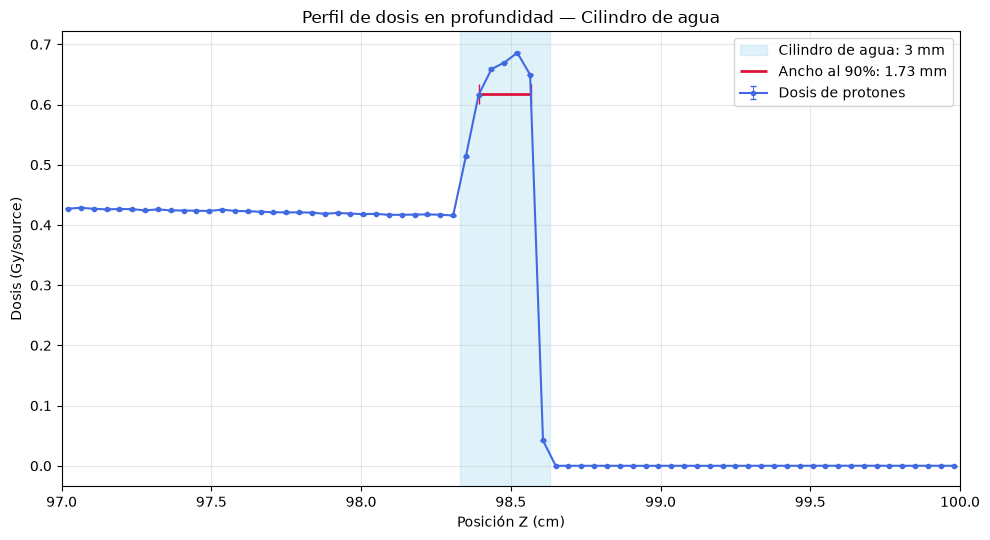

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

archivo = Path("../out/bragg_pouch_water.out")
fraccion = 0.90

datos = []
leyendo = False

for linea in archivo.read_text().splitlines():
    if linea.strip().startswith("#  z-lower"):
        leyendo = True
        continue

    if leyendo:
        if linea.strip().startswith("#   sum"):
            break

        valores = linea.split()

        if len(valores) == 4:
            try:
                datos.append([
                    float(v.replace("D", "E").replace("d", "e"))
                    for v in valores
                ])
            except ValueError:
                continue

if not datos:
    raise ValueError("No se encontraron datos del perfil de dosis.")

datos = np.array(datos)

z = (datos[:, 0] + datos[:, 1]) / 2
dosis = datos[:, 2]
error = dosis * datos[:, 3]

orden = np.argsort(z)
z = z[orden]
dosis = dosis[orden]
error = error[orden]

if not 0 < fraccion < 1:
    raise ValueError("La fracción debe estar entre 0 y 1.")

if dosis.max() <= 0:
    raise ValueError("La dosis máxima debe ser mayor que cero.")

umbral = fraccion * dosis.max()

imax = np.argmax(dosis)
izq = imax
der = imax

while izq > 0 and dosis[izq - 1] >= umbral:
    izq -= 1

while der < len(dosis) - 1 and dosis[der + 1] >= umbral:
    der += 1

if izq == 0 or der == len(dosis) - 1:
    raise ValueError("El perfil no contiene ambos cruces con el umbral.")

z_inicio = z[izq - 1] + (
    (umbral - dosis[izq - 1])
    / (dosis[izq] - dosis[izq - 1])
    * (z[izq] - z[izq - 1])
)

z_fin = z[der] + (
    (umbral - dosis[der])
    / (dosis[der + 1] - dosis[der])
    * (z[der + 1] - z[der])
)

ancho_mm = (z_fin - z_inicio) * 10

print(f"Umbral: {fraccion:.0%} del máximo")
print(f"Inicio: {z_inicio:.5f} cm")
print(f"Final: {z_fin:.5f} cm")
print(f"Ancho del SOBP: {ancho_mm:.3f} mm")

fig, ax = plt.subplots(figsize=(10, 5.5))

ax.errorbar(
    z, dosis, yerr=error,
    fmt="o-", color="royalblue",
    markersize=3, linewidth=1.5,
    capsize=2, elinewidth=0.7,
    label="Dosis de protones"
)

ax.axvspan(
    98.33, 98.63,
    color="skyblue", alpha=0.25,
    label="Cilindro de agua: 3 mm"
)

ax.hlines(
    umbral, z_inicio, z_fin,
    color="crimson", linewidth=2,
    label=f"Ancho al {fraccion:.0%}: {ancho_mm:.2f} mm"
)

ax.plot(
    [z_inicio, z_fin], [umbral, umbral],
    linestyle="none", marker="|",
    color="crimson", markersize=14
)

ax.set(
    title="Perfil de dosis en profundidad — Cilindro de agua",
    xlabel="Posición Z (cm)",
    ylabel="Dosis (Gy/source)"
)

ax.set_xlim(97, 100)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()